# 01 Dataset Exploration

This notebook explores the competition’s 63,660 labelled training images and 29,443 unlabelled test images for eight cat and dog facial-feature classes. It examines class balance, representative images, image dimensions and data quality, including exact duplicates, to guide preprocessing and model development.

## 1 Setup and data loading

The competition folders, image counts and file types are inspected before loading the training labels. These checks establish the dataset structure used throughout the subsequent notebooks.

In [1]:
import os
import pandas as pd

DATA_DIR = "/kaggle/input"
for root, dirs, files in os.walk(DATA_DIR):
    depth = root.replace(DATA_DIR, "").count(os.sep)
    if depth <= 3:
        print(root, "| subfolders:", len(dirs), "| files:", len(files), "| e.g.", files[:3])

/kaggle/input | subfolders: 1 | files: 0 | e.g. []
/kaggle/input/datasets | subfolders: 1 | files: 0 | e.g. []
/kaggle/input/datasets/khlafalshammari | subfolders: 1 | files: 0 | e.g. []
/kaggle/input/datasets/khlafalshammari/competition | subfolders: 2 | files: 2 | e.g. ['sample_submission.csv', 'train_labels.csv']


In [2]:
import os

BASE = "/kaggle/input/datasets/khlafalshammari/competition"

for name in sorted(os.listdir(BASE)):
    path = os.path.join(BASE, name)
    if os.path.isdir(path):
        items = os.listdir(path)
        n_subdirs = sum(os.path.isdir(os.path.join(path, i)) for i in items)
        print(f"{name}/ -> {len(items)} items ({n_subdirs} subfolders) | e.g. {sorted(items)[:5]}")
    else:
        print(f"{name} (file)")
        

sample_submission.csv (file)
test/ -> 1 items (1 subfolders) | e.g. ['test']
train/ -> 1 items (1 subfolders) | e.g. ['train']
train_labels.csv (file)


In [3]:
TRAIN_DIR = os.path.join(BASE, "train", "train")
TEST_DIR  = os.path.join(BASE, "test", "test")

train_files = sorted(os.listdir(TRAIN_DIR))
test_files  = sorted(os.listdir(TEST_DIR))

print("Train images:", len(train_files), "| e.g.", train_files[:5])
print("Test images: ", len(test_files),  "| e.g.", test_files[:5])

# File extensions present (checks for anything that isn't an image)
print("Train extensions:", pd.Series([os.path.splitext(f)[1].lower() for f in train_files]).value_counts().to_dict())
print("Test extensions: ", pd.Series([os.path.splitext(f)[1].lower() for f in test_files]).value_counts().to_dict())

# First look at the labels file
labels = pd.read_csv(os.path.join(BASE, "train_labels.csv"))
print("\nLabels shape:", labels.shape)
labels.head()

Train images: 63660 | e.g. ['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']
Test images:  29443 | e.g. ['00001.jpg', '00002.jpg', '00003.jpg', '00004.jpg', '00005.jpg']
Train extensions: {'.jpg': 63660}
Test extensions:  {'.jpg': 29443}

Labels shape: (63660, 2)


,image_id,class
0,1,DogEye
1,2,DogMouth
2,3,DogFace
3,4,DogNose
4,5,DogNose


## 2 Label checks and class distribution

Training labels are checked for missing values, repeated image IDs and unmatched image files. Class counts and proportions are then examined to identify imbalance across the eight categories.

In [4]:
# 1. Label quality checks
print("Missing values:\n", labels.isna().sum())
print("Duplicate image_ids:", labels["image_id"].duplicated().sum())
print("Unique classes:", sorted(labels["class"].unique()))

# 2. Does every label have a matching image file (and vice versa)?
expected_files = set(labels["image_id"].apply(lambda i: f"{i:05d}.jpg"))
actual_files = set(train_files)
print("Labels without an image:", len(expected_files - actual_files))
print("Images without a label: ", len(actual_files - expected_files))

# 3. Class distribution
counts = labels["class"].value_counts()
dist = pd.DataFrame({"count": counts, "percent": (counts / len(labels) * 100).round(2)})
print("\nLargest / smallest class ratio:", round(counts.max() / counts.min(), 2))
dist

Missing values:
 image_id    0
class       0
dtype: int64
Duplicate image_ids: 0
Unique classes: ['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']
Labels without an image: 0
Images without a label:  0

Largest / smallest class ratio: 2.4


,count,percent
class,,
CatEye,13884,21.81
DogEye,11580,18.19
CatNose,6942,10.90
CatFace,6942,10.90
CatMouth,6942,10.90
DogNose,5790,9.10
DogMouth,5790,9.10
DogFace,5790,9.10


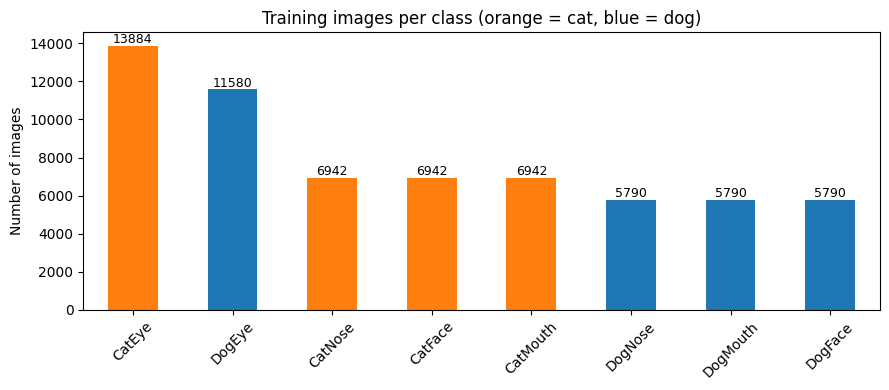

In [5]:
import matplotlib.pyplot as plt

colors = ["tab:orange" if c.startswith("Cat") else "tab:blue" for c in dist.index]
ax = dist["count"].plot(kind="bar", color=colors, figsize=(9, 4))
ax.set_title("Training images per class (orange = cat, blue = dog)")
ax.set_ylabel("Number of images")
ax.set_xlabel("")
for i, v in enumerate(dist["count"]):
    ax.text(i, v + 150, str(v), ha="center", fontsize=9)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 3 Sample images

Five images from each class are displayed using a fixed random seed. The examples illustrate variation in appearance, crop size and visual similarity between facial-feature classes.

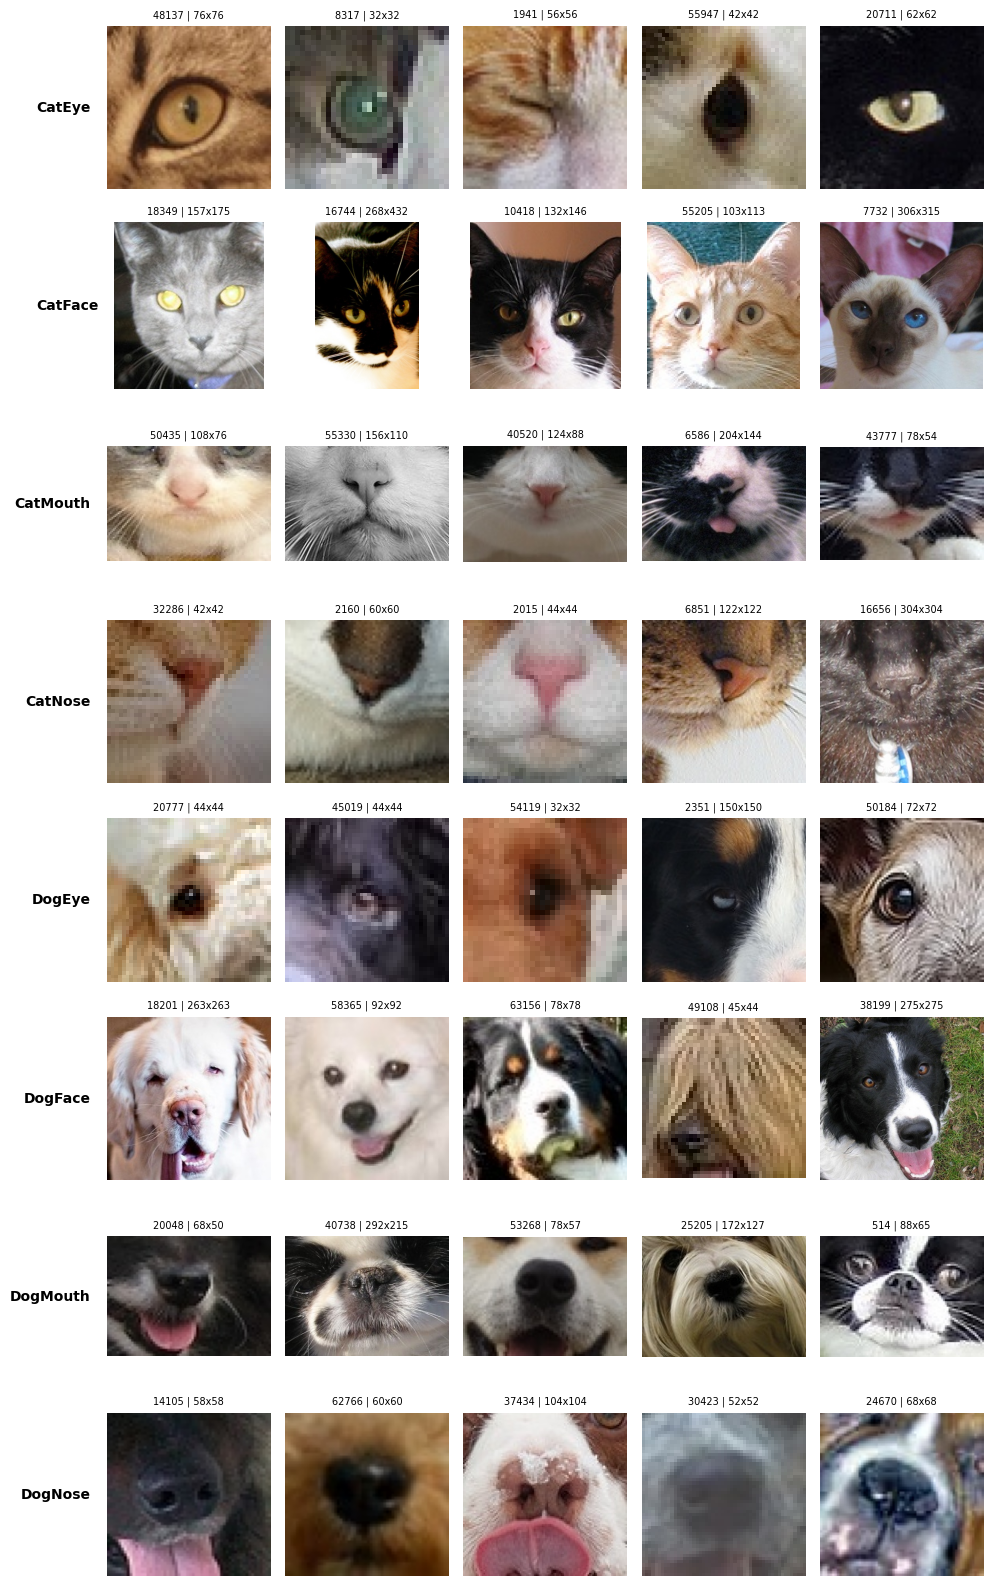

In [6]:
from PIL import Image
import random

random.seed(42)  # fixed seed so the same samples appear every run (reproducibility)
classes = sorted(labels["class"].unique())
n_per_class = 5

fig, axes = plt.subplots(len(classes), n_per_class, figsize=(n_per_class * 2, len(classes) * 2))
for row, cls in enumerate(classes):
    ids = labels.loc[labels["class"] == cls, "image_id"].tolist()
    for col, img_id in enumerate(random.sample(ids, n_per_class)):
        img = Image.open(os.path.join(TRAIN_DIR, f"{img_id:05d}.jpg"))
        ax = axes[row, col]
        ax.imshow(img)
        ax.set_title(f"{img_id} | {img.size[0]}x{img.size[1]}", fontsize=7)
        ax.axis("off")
    axes[row, 0].text(-0.1, 0.5, cls, transform=axes[row, 0].transAxes,
                      ha="right", va="center", fontsize=10, fontweight="bold")
plt.tight_layout()
plt.show()

## 4 Image dimensions and aspect ratios

Image dimensions and aspect ratios are summarised to guide input resizing and augmentation. A sequence of neighbouring image IDs is also inspected for possible related crops; this visual check does not establish source-animal groups.

         width   height
count  63660.0  63660.0
mean     113.1    109.7
std       98.5    101.9
min        4.0      4.0
25%       54.0     50.0
50%       84.0     80.0
75%      138.0    130.0
max     2219.0   2219.0

Median size and aspect ratio per class:
          width  height  aspect
class                          
CatEye     68.0    68.0    1.00
CatFace   182.0   215.0    0.83
CatMouth  114.0    80.0    1.42
CatNose    68.0    68.0    1.00
DogEye     62.0    62.0    1.00
DogFace   155.0   155.0    1.00
DogMouth  104.0    77.0    1.35
DogNose    62.0    62.0    1.00

Images smaller than 64 px on the shortest side: 37.2 %


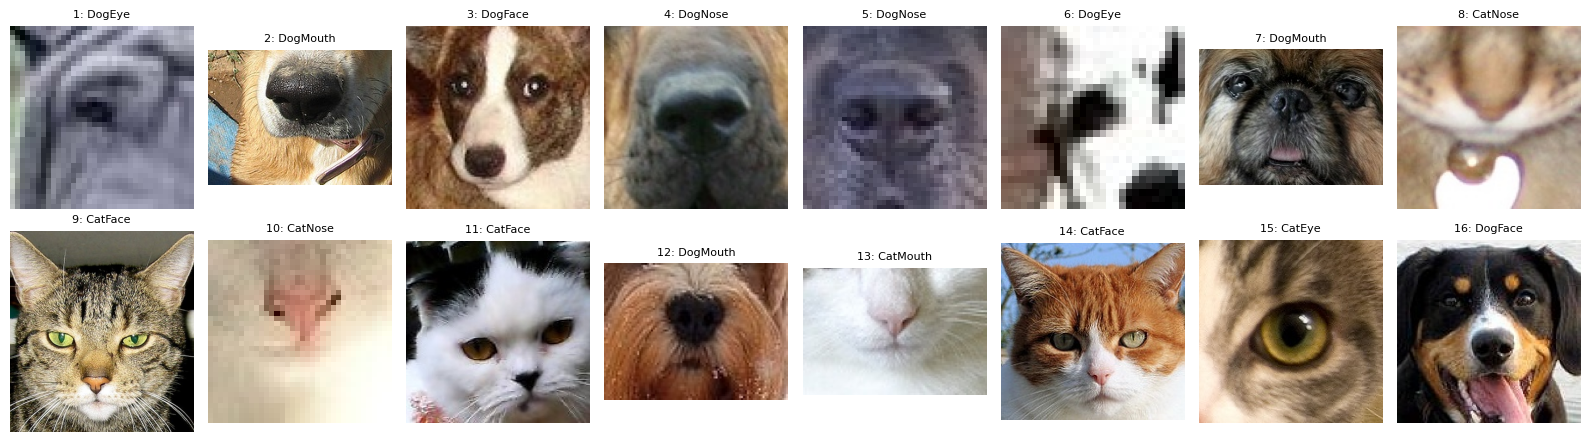

In [7]:
# 1. Image size statistics for every training image (takes ~1 min: PIL only reads headers)
sizes = [Image.open(os.path.join(TRAIN_DIR, f"{i:05d}.jpg")).size for i in labels["image_id"]]
labels["width"]  = [s[0] for s in sizes]
labels["height"] = [s[1] for s in sizes]
labels["aspect"] = (labels["width"] / labels["height"]).round(2)

print(labels[["width", "height"]].describe().round(1))
print("\nMedian size and aspect ratio per class:")
print(labels.groupby("class")[["width", "height", "aspect"]].median())
print("\nImages smaller than 64 px on the shortest side:",
      (labels[["width", "height"]].min(axis=1) < 64).mean().round(3) * 100, "%")

# 2. Consecutive IDs: do neighbouring images come from the same animal?
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, img_id in zip(axes.flat, range(1, 17)):
    ax.imshow(Image.open(os.path.join(TRAIN_DIR, f"{img_id:05d}.jpg")))
    ax.set_title(f"{img_id}: {labels.loc[labels.image_id == img_id, 'class'].item()}", fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5 Data quality and duplicate checks

Training images are checked for corruption and colour mode, while file hashes identify exact duplicates and any conflicting labels. Counts of very small crops help assess the need for low-resolution augmentation.

In [8]:
import hashlib
from tqdm.auto import tqdm

modes, hashes, corrupted = [], [], []
for i in tqdm(labels["image_id"]):
    path = os.path.join(TRAIN_DIR, f"{i:05d}.jpg")
    try:
        with Image.open(path) as img:
            img.verify()                 # checks the file isn't corrupted
        with Image.open(path) as img:
            modes.append(img.mode)       # RGB = colour, L = greyscale
        with open(path, "rb") as f:
            hashes.append(hashlib.md5(f.read()).hexdigest())  # fingerprint of the file's bytes
    except Exception as e:
        corrupted.append(i); modes.append(None); hashes.append(None)

labels["mode"] = modes
labels["md5"] = hashes

print("Corrupted files:", len(corrupted))
print("Colour modes:", labels["mode"].value_counts().to_dict())

short_side = labels[["width", "height"]].min(axis=1)
for t in [16, 32, 64]:
    print(f"Shortest side < {t}px: {(short_side < t).sum()} images")

dup = labels[labels["md5"].duplicated(keep=False)]
print("\nExact duplicate images:", dup["md5"].duplicated().sum())
conflicts = dup.groupby("md5")["class"].nunique()
print("Duplicate groups with CONFLICTING labels:", (conflicts > 1).sum())

  0%|          | 0/63660 [00:00<?, ?it/s]

Corrupted files: 0
Colour modes: {'RGB': 63660}
Shortest side < 16px: 190 images
Shortest side < 32px: 4130 images
Shortest side < 64px: 23698 images

Exact duplicate images: 15
Duplicate groups with CONFLICTING labels: 0


## 6 Dataset cleaning, test comparison and metadata export

Redundant exact duplicates are removed, retaining one image per identical file hash. Training and test image sizes are compared without using test labels, and the cleaned training metadata is exported for subsequent modelling.

In [9]:
# 1. Remove exact duplicates (keep the first copy of each)
before = len(labels)
labels_clean = labels.drop_duplicates(subset="md5", keep="first").reset_index(drop=True)
print(f"Removed {before - len(labels_clean)} duplicates -> {len(labels_clean)} training images")

# 2. Test image sizes (no labels involved - just checking train and test look alike)
test_sizes = [Image.open(os.path.join(TEST_DIR, f)).size for f in tqdm(test_files)]
test_short = pd.Series([min(s) for s in test_sizes])
train_short = labels_clean[["width", "height"]].min(axis=1)
print(pd.DataFrame({
    "train": train_short.describe().round(1),
    "test": test_short.describe().round(1)
}))
print(f"\n<32px  train: {(train_short < 32).mean()*100:.1f}%   test: {(test_short < 32).mean()*100:.1f}%")

# 3. Save the cleaned metadata for the next notebooks
labels_clean.to_csv("/kaggle/working/train_metadata_clean.csv", index=False)
print("Saved train_metadata_clean.csv")

Removed 15 duplicates -> 63645 training images


  0%|          | 0/29443 [00:00<?, ?it/s]

         train     test
count  63645.0  29443.0
mean     105.1    103.5
std       92.5     94.4
min        4.0      8.0
25%       50.0     49.0
50%       78.0     77.0
75%      126.0    124.0
max     2219.0   1832.0

<32px  train: 6.5%   test: 8.2%
Saved train_metadata_clean.csv


## Task 1 Summary: Dataset Exploration

**Problem.** Eight-class image classification of cat and dog facial features
(CatEye, CatFace, CatMouth, CatNose, DogEye, DogFace, DogMouth, DogNose).
Evaluation metric: accuracy on the hidden Kaggle test labels.

**Structure.** 63,660 labelled training images and 29,443 unlabelled test images, all JPEG.
`train_labels.csv` maps integer `image_id` to class; filenames are zero-padded (`00001.jpg`).
Train and test reuse the same filenames, so full folder paths are always used.

**Label quality.** No missing values, no duplicate IDs, exactly 8 consistently spelled classes,
and a perfect one-to-one match between labels and image files.

**Class distribution.** Moderately imbalanced (largest/smallest ratio = 2.4).
Eye classes are exactly twice the size of the other features of the same species
(CatEye 13,884 = 2 × 6,942; DogEye 11,580 = 2 × 5,790), suggesting each source photo
was cropped into one face, nose and mouth and two eyes. Majority-class baseline accuracy ≈ 21.8%.

**Image quality.**
- Sizes vary from 4×4 to 2219×2219 px (median ≈ 84×80); 37.2% are under 64 px on the shortest side,
  and many are visibly pixelated.
- Aspect ratio differs by class: mouths are wide (≈1.4), CatFace is portrait (0.83), others square.
- No corrupted files; all images are RGB.
- 15 exact duplicates (MD5 hash), none with conflicting labels.
- Some class boundaries are unclear: mouth crops usually include the nose, and some nose crops show the
  tongue. Nose/Mouth confusion is expected.

**Decisions.**
- Removed the 15 duplicates (63,645 images remain) to prevent leakage between training and validation.
- Kept tiny images: the test set has a similar size distribution with slightly more tiny images
  (8.2% vs 6.5% under 32 px), so the model must learn to handle them.

**Data usage plan.** Stratified 85/15 train/validation split with a fixed random seed to preserve
class proportions. The test set is used only to generate the final Kaggle submission.

**Limitation.** Image IDs are shuffled, so crops from the same source photo cannot be grouped.
A random split may place, for example, both eyes of one cat across train and validation,
making validation accuracy slightly optimistic. This will be checked by comparing
validation accuracy with the Kaggle leaderboard score.